In [21]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
from sklearn.utils import Bunch
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score

In [3]:
mnist = fetch_openml('mnist_784', as_frame = False)
# False is for the dataset of MNIST to come out as a Numpy array and not a default Dataframe

In [4]:
x,y = mnist.data, mnist.target

In [5]:
x.shape,y.shape

((70000, 784), (70000,))

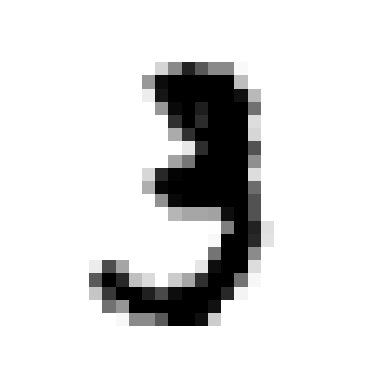

In [19]:
def plot_digit(image_data):
    image = image_data.reshape(28,28)
    plt.imshow(image, cmap = "binary")
    plt.axis("off")

some_digit = x[10]
plot_digit(some_digit)
plt.show()

# Keeping the training and test side aside before inspecting the training set
x_train, x_test, y_train, y_test = x[:60000], x[60000:], y[:60000], y[60000:]

In [20]:
# Classifying between classes of 5 and non-5.
y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')

sgd_clf = SGDClassifier(random_state = 42)
sgd_clf.fit(x_train, y_train_5)
sgd_clf.predict([some_digit])

array([False])

In [34]:
score = cross_val_score(sgd_clf, x_train, y_train_5, cv = 3, scoring = "accuracy")
print(score)

[0.95035 0.96035 0.9604 ]


In [24]:
score.mean(), score.std()

(np.float64(0.9570333333333334), np.float64(0.004725874404688398))

In [28]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier()
dummy_clf.fit(x_train, y_train_5)
print(any(dummy_clf.predict(x_train)))
cross_val_score(dummy_clf, x_train, y_train_5, cv = 3, scoring = "accuracy")

False


array([0.90965, 0.90965, 0.90965])

In [35]:
# Implementing Cross Validation using StratifiedKFold
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits = 3)

for train_index, test_index in skfolds.split(x_train, y_train_5):
    clone_clf = clone(sgd_clf)
    x_train_folds = x_train[train_index]
    y_train_folds = y_train_5[train_index]
    x_test_fold = x_train[test_index]
    y_test_fold = y_train_5[test_index]

    clone_clf.fit(x_train_folds, y_train_folds)
    y_pred = clone_clf.predict(x_test_fold)
    n_correct = sum(y_pred == y_test_fold)

    print(n_correct / len(y_pred))
# Both the cross_val_score and StratifiedKFold give the same results.

0.95035
0.96035
0.9604
